## Importing the libraries

In [186]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Importing the Datasets

In [187]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

## Exploratory Data Analysis

In [188]:
train_df.shape

(891, 12)

In [189]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [190]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Which columns have missing values, and how many in each?

In [191]:
train_df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### What percentage of each column is missing?

In [192]:
(train_df.isna().sum()/len(train_df)) * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

### Which column is so sparse you would probably not use it directly?

### For Age, what would be a reasonable way to fill the gaps, and why? You can write this down and not apply it yet.

### Could the data be missing for a reason, for example that missing Cabin is related to class?

In [193]:
train_df.groupby(["Pclass"])["Cabin"].value_counts()

Pclass  Cabin      
1       B96 B98        4
        C23 C25 C27    4
        C22 C26        3
        B18            2
        B20            2
                      ..
3       F G73          2
        E10            1
        F E69          1
        F G63          1
        F38            1
Name: count, Length: 147, dtype: int64

### What is the overall survival rate?

In [194]:
train_df["Survived"].mean()

np.float64(0.3838383838383838)

### How does survival differ by sex? By passenger class? By port of embarkation?

In [195]:
train_df.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [196]:
train_df.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [197]:
train_df.groupby("Embarked")["Survived"].mean()

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

### How does survival differ across age groups? You’ll need to decide the bins yourself.

In [198]:
train_df["Agegroup"] = pd.cut(x = train_df["Age"], bins = [0, 12, 18, 35, 60, 100], labels=["0-12", "13-18", "19-35", "36-60", "60+"])

In [199]:
train_df["Agegroup"].value_counts()

Agegroup
19-35    358
36-60    195
13-18     70
0-12      69
60+       22
Name: count, dtype: int64

### Does survival change with family size (SibSp + Parch + 1)?

In [200]:
train_df["FamilySize"] = train_df["SibSp"] + train_df["Parch"] + 1

In [201]:
train_df.groupby("FamilySize")["Survived"].mean()

FamilySize
1     0.303538
2     0.552795
3     0.578431
4     0.724138
5     0.200000
6     0.136364
7     0.333333
8     0.000000
11    0.000000
Name: Survived, dtype: float64

### Within each class, does the gap between men and women stay the same?

In [202]:
train_df.groupby("Pclass")["Sex"].value_counts()

Pclass  Sex   
1       male      122
        female     94
2       male      108
        female     76
3       male      347
        female    144
Name: count, dtype: int64

In [203]:
male = train_df.groupby("Pclass")["Sex"].value_counts().loc[(1, "male")]
female = train_df.groupby("Pclass")["Sex"].value_counts().loc[(1, "female")]

In [204]:
train_df.groupby("Pclass")["Sex"].value_counts().unstack()

Sex,female,male
Pclass,,
1,94,122
2,76,108
3,144,347


### Which group had the highest survival rate, and which had the lowest?

## Visualizations

### How much of each column is missing?

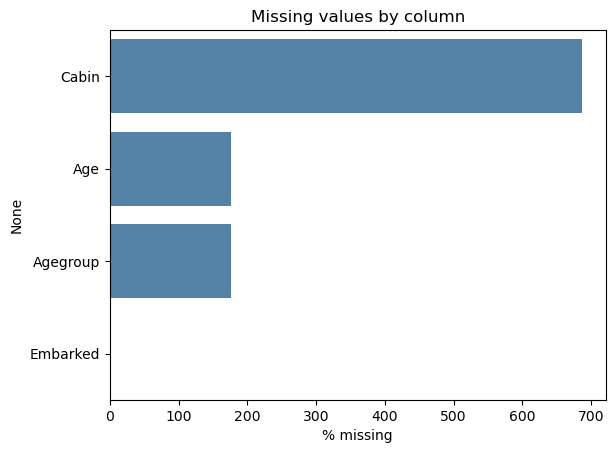

In [205]:
null_values = train_df.isna().sum()
m = null_values[null_values>0].sort_values(ascending=False)
sns.barplot(x = m.values, y = m.index, color="steelblue")
plt.xlabel("% missing")
plt.title("Missing values by column")
plt.show()

### How does survival rate differ by sex?

Text(0.5, 1.0, 'Survival by Sex')

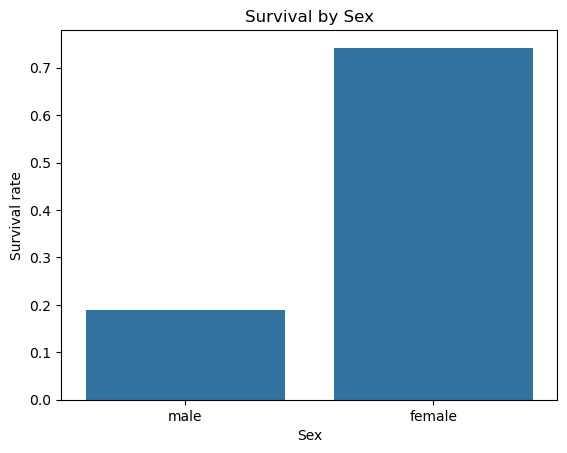

In [206]:
sns.barplot(data = train_df, x="Sex", y="Survived", errorbar=None)
plt.ylabel("Survival rate")
plt.title("Survival by Sex")

### How does survival rate differ by class and sex together?

Text(0.5, 1.0, 'Survival by Sex and Class')

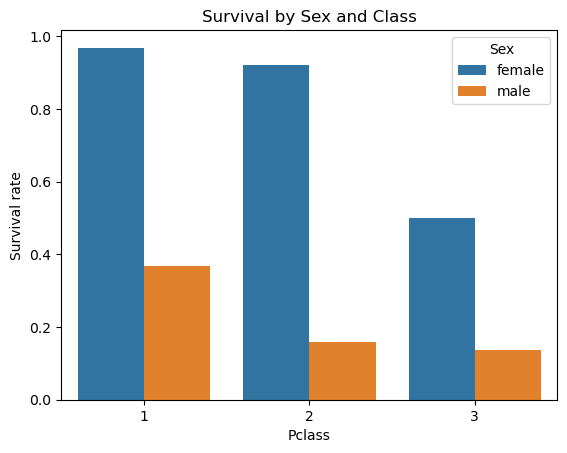

In [207]:
sns.barplot(data = train_df, x="Pclass", y="Survived", hue="Sex", errorbar=None)
plt.ylabel("Survival rate")
plt.title("Survival by Sex and Class")

### How does the age distribution differ between survivors and non-survivors?

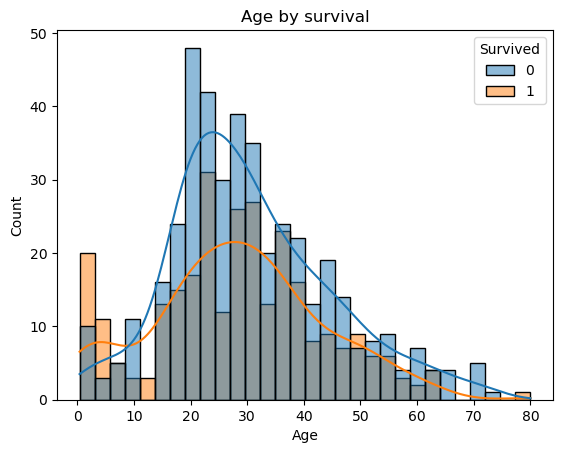

In [208]:
sns.histplot(data=train_df.dropna(subset=["Age"]), x="Age", hue="Survived", bins=30, kde=True)
plt.title("Age by survival")
plt.show()

### How does survival rate change with family size?

Text(0.5, 1.0, 'Survival by FamilySize')

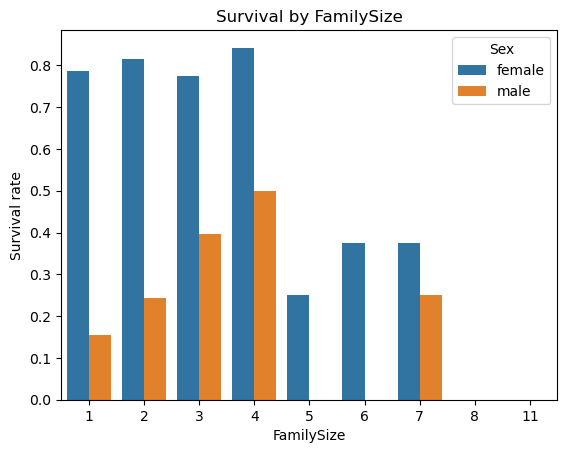

In [209]:
sns.barplot(x=train_df["FamilySize"], y=train_df["Survived"], hue=train_df["Sex"], errorbar=None)
plt.ylabel("Survival rate")
plt.title("Survival by FamilySize")

## Data Cleaning

In [210]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    int64   
 2   Pclass       891 non-null    int64   
 3   Name         891 non-null    object  
 4   Sex          891 non-null    object  
 5   Age          714 non-null    float64 
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    object  
 9   Fare         891 non-null    float64 
 10  Cabin        204 non-null    object  
 11  Embarked     889 non-null    object  
 12  Agegroup     714 non-null    category
 13  FamilySize   891 non-null    int64   
dtypes: category(1), float64(2), int64(6), object(5)
memory usage: 91.7+ KB


In [211]:
train_df.head(1)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Agegroup,FamilySize
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S,19-35,2


In [212]:
names = train_df["Name"].apply(lambda x: x.split(","))

In [214]:
names

0                             [Braund,  Mr. Owen Harris]
1      [Cumings,  Mrs. John Bradley (Florence Briggs ...
2                              [Heikkinen,  Miss. Laina]
3        [Futrelle,  Mrs. Jacques Heath (Lily May Peel)]
4                            [Allen,  Mr. William Henry]
                             ...                        
886                             [Montvila,  Rev. Juozas]
887                      [Graham,  Miss. Margaret Edith]
888          [Johnston,  Miss. Catherine Helen "Carrie"]
889                             [Behr,  Mr. Karl Howell]
890                               [Dooley,  Mr. Patrick]
Name: Name, Length: 891, dtype: object

In [224]:
titles = train_df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
titles.replace({"Ms": "Miss", "Mme": "Mrs", "Mlle": "Miss"})
common = ["Mr", "Miss", "Mrs", "Master"]
train_df["title"] = titles.where(titles.isin(common), "Rare")
train_df["title"]

0        Mr
1       Mrs
2      Miss
3       Mrs
4        Mr
       ... 
886    Rare
887    Miss
888    Miss
889      Mr
890      Mr
Name: title, Length: 891, dtype: object

In [230]:
train_df["isalone"] = (train_df["FamilySize"]==1).astype(int)
train_df["hasCabin"] = train_df["Cabin"].notna().astype(int)

In [232]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Agegroup,FamilySize,title,isalone,hasCabin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,19-35,2,Mr,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,36-60,2,Mrs,0,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,19-35,1,Miss,1,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,19-35,2,Mrs,0,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,19-35,1,Mr,1,0


In [233]:
train_df.drop(columns=["PassengerId", "Name", "Ticket"], inplace=True)

In [234]:
train_df["Age"] = train_df["Age"].fillna(train_df.groupby(["Pclass", "Sex"])["Age"].transform("median"))

In [235]:
train_df.drop(columns=["Cabin"], inplace=True)

In [236]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Survived    891 non-null    int64   
 1   Pclass      891 non-null    int64   
 2   Sex         891 non-null    object  
 3   Age         891 non-null    float64 
 4   SibSp       891 non-null    int64   
 5   Parch       891 non-null    int64   
 6   Fare        891 non-null    float64 
 7   Embarked    889 non-null    object  
 8   Agegroup    714 non-null    category
 9   FamilySize  891 non-null    int64   
 10  title       891 non-null    object  
 11  isalone     891 non-null    int64   
 12  hasCabin    891 non-null    int64   
dtypes: category(1), float64(2), int64(7), object(3)
memory usage: 84.7+ KB


In [237]:
embarked_mode = train_df["Embarked"].mode()[0]
train_df["Embarked"] = train_df["Embarked"].fillna(embarked_mode)

In [247]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics  import accuracy_score, classification_report

In [252]:
scale = ["Sex", "Embarked", "title", "Pclass"]
train_df["Pclass"] = train_df["Pclass"].astype(str)          # so get_dummies treats it as a category
train_df = pd.get_dummies(train_df, columns=scale, drop_first=True)

In [256]:
num = ["Age", "Fare", "FamilySize"]
train_df[num] = StandardScaler().fit_transform(train_df[num])
train_df

,Survived,Age,SibSp,Parch,Fare,Agegroup,FamilySize,isalone,hasCabin,Sex_male,Embarked_Q,Embarked_S,title_Miss,title_Mr,title_Mrs,title_Rare,Pclass_2,Pclass_3
0,0,-0.534891,1,0,-0.502445,19-35,0.059160,0,0,True,False,True,False,True,False,False,False,True
1,1,0.668392,1,0,0.786845,36-60,0.059160,0,1,False,False,False,False,False,True,False,False,False
2,1,-0.234070,0,0,-0.488854,19-35,-0.560975,1,0,False,False,True,True,False,False,False,False,True
3,1,0.442776,1,0,0.420730,19-35,0.059160,0,1,False,False,True,False,False,True,False,False,False
4,0,0.442776,0,0,-0.486337,19-35,-0.560975,1,0,True,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,-0.158865,0,0,-0.386671,19-35,-0.560975,1,0,True,False,True,False,False,False,True,True,False
887,1,-0.760507,0,0,-0.044381,19-35,-0.560975,1,1,False,False,True,True,False,False,False,False,False
888,0,-0.572494,1,2,-0.176263,NaN,1.299429,0,0,False,False,True,True,False,False,False,False,True
889,1,-0.234070,0,0,-0.044381,19-35,-0.560975,1,1,True,False,False,False,True,False,False,False,False


In [261]:

X_train = train_df.drop(columns=["Survived", "Agegroup"])
Y_train = train_df["Survived"]

In [262]:
X_test = test_df

In [263]:
model = LogisticRegression(max_iter = 200)
model.fit(X_train, Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [264]:
print("train", accuracy_score(Y_train, model.predict(X_train)))

train 0.8327721661054994
